In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
from google.colab import files

uploaded = files.upload()

Saving hospital_data_sampleee.xlsx to hospital_data_sampleee.xlsx


In [3]:
df = pd.read_excel(next(iter(uploaded)))

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset Shape: (29998, 11)

Columns:
['Date', ' Medication Revenue ', '  Lab Cost ', ' Consultation Revenue ', 'Doctor Type', 'Financial Class', 'Patient Type', 'Entry Time', 'Post-Consultation Time', 'Completion Time', 'Patient ID']


,Date,Medication Revenue,Lab Cost,Consultation Revenue,Doctor Type,Financial Class,Patient Type,Entry Time,Post-Consultation Time,Completion Time,Patient ID
0,2019-11-04,1183.22,10,20.17,ANCHOR,HMO,OUTPATIENT,08:35:45,09:17:54,09:29:46,C10001
1,2019-11-06,738.48,$-,15,ANCHOR,INSURANCE,OUTPATIENT,19:19:16,21:02:36,21:24:07,C10002
2,2019-11-02,660,$-,21.17,ANCHOR,HMO,OUTPATIENT,10:46:52,11:56:25,12:06:28,C10003
3,2019-11-06,600,$-,$-,ANCHOR,MEDICARE,OUTPATIENT,09:38:34,10:55:50,10:58:02,C10004
4,2019-11-01,591.6,$-,12,ANCHOR,INSURANCE,OUTPATIENT,11:16:21,12:06:49,12:06:54,C10005


In [4]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Date', 'Medication Revenue', 'Lab Cost', 'Consultation Revenue', 'Doctor Type', 'Financial Class', 'Patient Type', 'Entry Time', 'Post-Consultation Time', 'Completion Time', 'Patient ID']


In [5]:
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("Duplicate Patient IDs:", df['Patient ID'].duplicated().sum())
print("\nDoctor Types:")
print(df['Doctor Type'].value_counts())

print("\nPatient Types:")
print(df['Patient Type'].value_counts())

print("\nFinancial Classes:")
print(df['Financial Class'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29998 entries, 0 to 29997
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Date                    29998 non-null  datetime64[ns]
 1   Medication Revenue      29998 non-null  object        
 2   Lab Cost                29998 non-null  object        
 3   Consultation Revenue    29998 non-null  object        
 4   Doctor Type             29998 non-null  object        
 5   Financial Class         29998 non-null  object        
 6   Patient Type            29998 non-null  object        
 7   Entry Time              29998 non-null  object        
 8   Post-Consultation Time  29998 non-null  object        
 9   Completion Time         29998 non-null  object        
 10  Patient ID              29998 non-null  object        
dtypes: datetime64[ns](1), object(10)
memory usage: 2.5+ MB
None

Missing Values:
Date                      0
M

In [7]:
df['Appointment_Time'] = pd.to_datetime(
    df['Date'].astype(str) + ' ' + df['Entry Time'].astype(str),
    errors='coerce'
)

df['Consultation_Time'] = pd.to_datetime(
    df['Date'].astype(str) + ' ' + df['Post-Consultation Time'].astype(str),
    errors='coerce'
)

df['Discharge_Time'] = pd.to_datetime(
    df['Date'].astype(str) + ' ' + df['Completion Time'].astype(str),
    errors='coerce'
)
df[
    ['Date',
     'Appointment_Time',
     'Consultation_Time',
     'Discharge_Time']
].head()

,Date,Appointment_Time,Consultation_Time,Discharge_Time
0,2019-11-04,2019-11-04 08:35:45,2019-11-04 09:17:54,2019-11-04 09:29:46
1,2019-11-06,2019-11-06 19:19:16,2019-11-06 21:02:36,2019-11-06 21:24:07
2,2019-11-02,2019-11-02 10:46:52,2019-11-02 11:56:25,2019-11-02 12:06:28
3,2019-11-06,2019-11-06 09:38:34,2019-11-06 10:55:50,2019-11-06 10:58:02
4,2019-11-01,2019-11-01 11:16:21,2019-11-01 12:06:49,2019-11-01 12:06:54


In [9]:
df['Doctor_Wait_Minutes'] = (
    df['Consultation_Time'] -
    df['Appointment_Time']
).dt.total_seconds() / 60
df['Post_Consultation_Duration_Minutes'] = (
    df['Discharge_Time'] -
    df['Consultation_Time']
).dt.total_seconds() / 60
df['Total_OPD_Time_Minutes'] = (
    df['Discharge_Time'] -
    df['Appointment_Time']
).dt.total_seconds() / 60
df['Appointment_Hour'] = df['Appointment_Time'].dt.hour

df['Appointment_Minute'] = df['Appointment_Time'].dt.minute

df['Day_of_Week'] = df['Appointment_Time'].dt.day_name()

df['Day_Number'] = df['Appointment_Time'].dt.dayofweek

df['Is_Weekend'] = df['Day_Number'] >= 5
df[
    ['Appointment_Time',
     'Appointment_Hour',
     'Day_of_Week',
     'Is_Weekend']
].head()

,Appointment_Time,Appointment_Hour,Day_of_Week,Is_Weekend
0,2019-11-04 08:35:45,8,Monday,False
1,2019-11-06 19:19:16,19,Wednesday,False
2,2019-11-02 10:46:52,10,Saturday,True
3,2019-11-06 09:38:34,9,Wednesday,False
4,2019-11-01 11:16:21,11,Friday,False


In [10]:
invalid_records = df[
    (df['Consultation_Time'] < df['Appointment_Time']) |
    (df['Discharge_Time'] < df['Consultation_Time'])
]

print("Invalid timestamp records:", len(invalid_records))
df_clean = df[
    (df['Consultation_Time'] >= df['Appointment_Time']) &
    (df['Discharge_Time'] >= df['Consultation_Time'])
].copy()

Invalid timestamp records: 389


In [11]:
df_clean[
    [
        'Doctor_Wait_Minutes',
        'Post_Consultation_Duration_Minutes',
        'Total_OPD_Time_Minutes'
    ]
].describe()

,Doctor_Wait_Minutes,Post_Consultation_Duration_Minutes,Total_OPD_Time_Minutes
count,29609.000000,29609.000000,29609.000000
mean,37.860206,5.962134,43.822340
std,40.259725,16.976122,44.488700
min,0.566667,0.016667,1.050000
25%,13.850000,0.700000,17.433333
50%,26.066667,2.333333,30.933333
75%,48.250000,5.416667,54.433333
max,733.333333,470.316667,733.533333


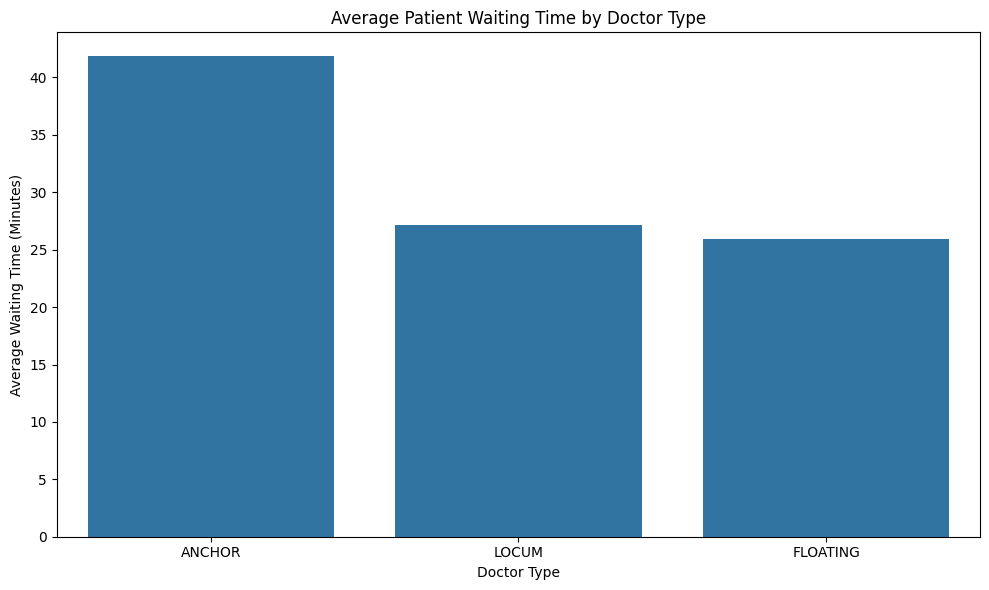

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x='Doctor Type',
    y='Doctor_Wait_Minutes',
    estimator='mean',
    errorbar=None
)

plt.title('Average Patient Waiting Time by Doctor Type')
plt.xlabel('Doctor Type')
plt.ylabel('Average Waiting Time (Minutes)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

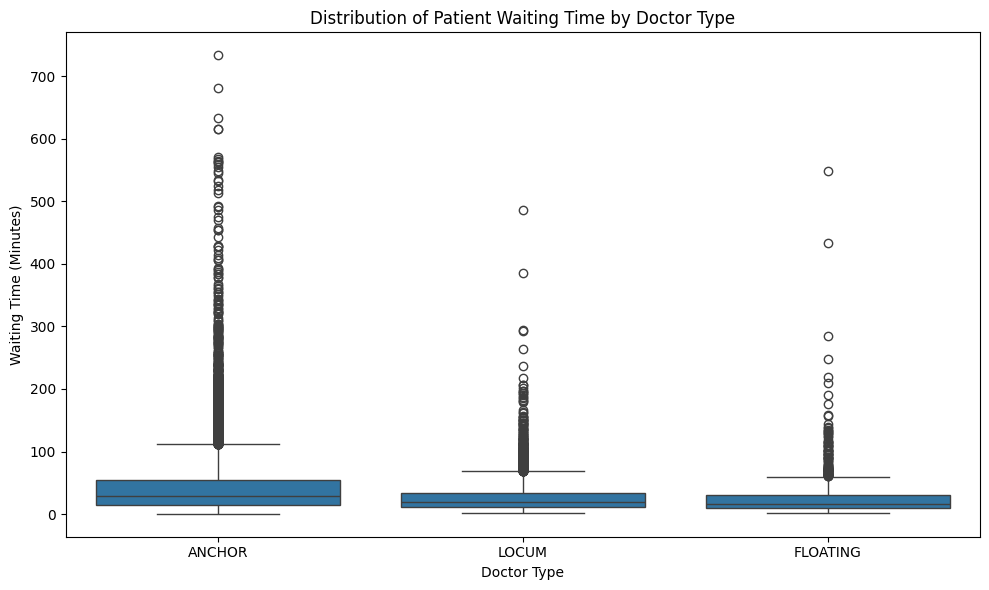

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='Doctor Type',
    y='Doctor_Wait_Minutes'
)

plt.title('Distribution of Patient Waiting Time by Doctor Type')
plt.xlabel('Doctor Type')
plt.ylabel('Waiting Time (Minutes)')
plt.tight_layout()
plt.show()

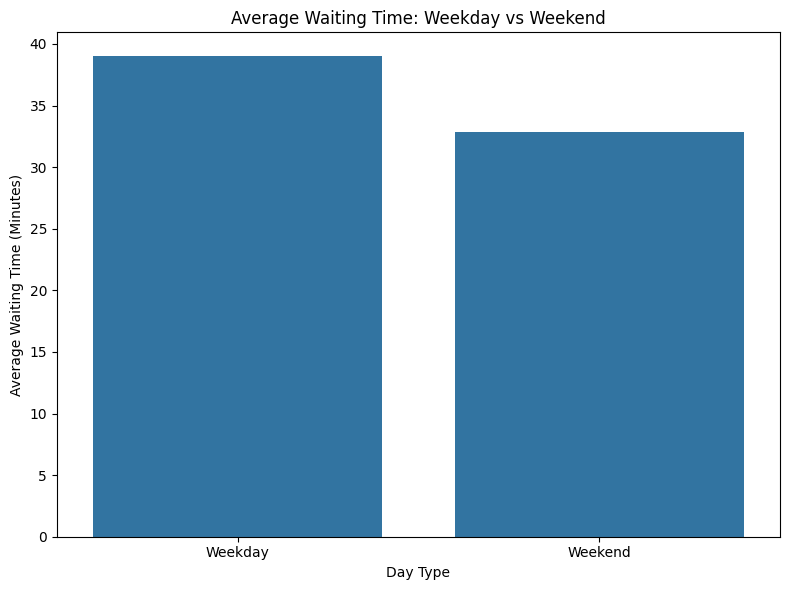

In [14]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df_clean,
    x='Is_Weekend',
    y='Doctor_Wait_Minutes',
    estimator='mean',
    errorbar=None
)

plt.title('Average Waiting Time: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Waiting Time (Minutes)')

plt.xticks(
    [0, 1],
    ['Weekday', 'Weekend']
)

plt.tight_layout()
plt.show()

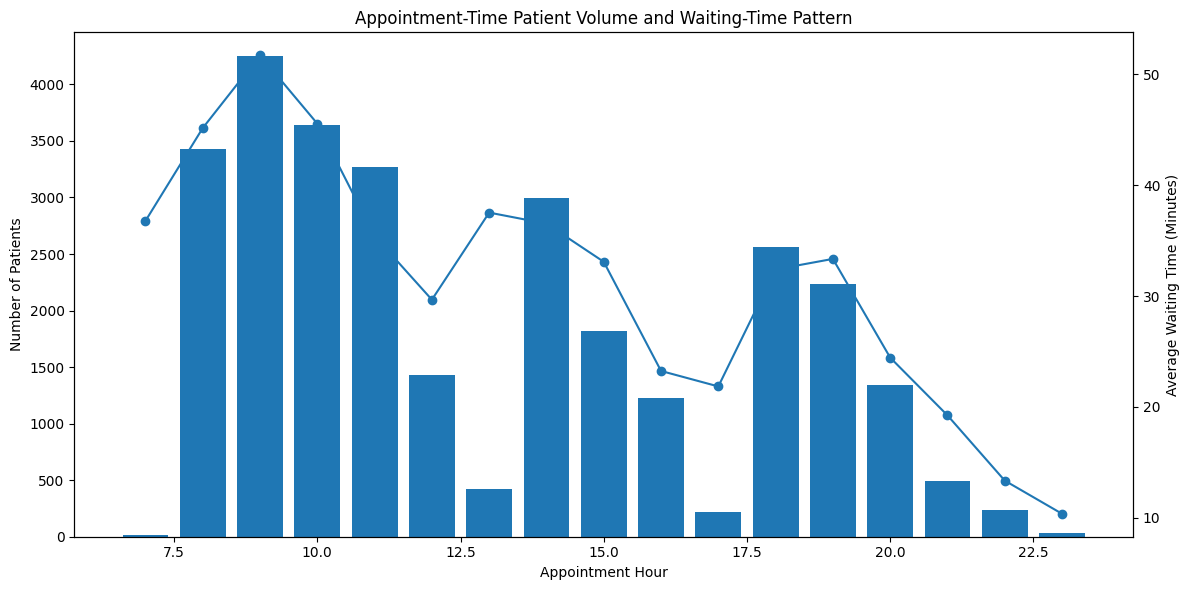

In [15]:
hourly = df_clean.groupby('Appointment_Hour').agg(
    Patient_Count=('Patient ID', 'count'),
    Average_Wait=('Doctor_Wait_Minutes', 'mean')
).reset_index()

hourly
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    hourly['Appointment_Hour'],
    hourly['Patient_Count']
)

ax1.set_xlabel('Appointment Hour')
ax1.set_ylabel('Number of Patients')

ax1.set_title('Appointment-Time Patient Volume and Waiting-Time Pattern')

ax2 = ax1.twinx()

ax2.plot(
    hourly['Appointment_Hour'],
    hourly['Average_Wait'],
    marker='o'
)

ax2.set_ylabel('Average Waiting Time (Minutes)')

plt.tight_layout()
plt.show()

In [16]:
features = [
    'Doctor Type',
    'Financial Class',
    'Appointment_Hour',
    'Appointment_Minute',
    'Day_of_Week',
    'Is_Weekend'
]

target = 'Doctor_Wait_Minutes'

X = df_clean[features]
y = df_clean[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Features:
['Doctor Type', 'Financial Class', 'Appointment_Hour', 'Appointment_Minute', 'Day_of_Week', 'Is_Weekend']

Target:
Doctor_Wait_Minutes

X Shape: (29609, 6)
y Shape: (29609,)


In [17]:
train_dates = df_clean['Date'].dt.date <= pd.Timestamp('2019-11-10').date()
test_dates = df_clean['Date'].dt.date > pd.Timestamp('2019-11-10').date()

X_train = df_clean.loc[train_dates, features]
y_train = df_clean.loc[train_dates, target]

X_test = df_clean.loc[test_dates, features]
y_test = df_clean.loc[test_dates, target]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 21832
Testing samples: 7777


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    'Doctor Type',
    'Financial Class',
    'Day_of_Week'
]

numeric_features = [
    'Appointment_Hour',
    'Appointment_Minute',
    'Is_Weekend'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numeric',
            'passthrough',
            numeric_features
        )
    ]
)

In [21]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=3,
    max_features='sqrt',
    n_jobs=-1
)
from sklearn.pipeline import Pipeline

model_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('random_forest', rf_model)
    ]
)
model_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [22]:
y_pred = model_pipeline.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[ 96.26666667  44.5         18.55        19.9         65.95
  16.7         20.33333333 104.06666667  58.23333333 105.73333333]

First 10 predicted values:
[69.29970966 38.98008823 37.52566136 31.07404761 33.07232601 26.48912218
 78.4299662  36.09132779 79.81462071 47.78051884]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Random Forest Evaluation")
print("------------------------")
print(f"MAE  : {mae:.2f} minutes")
print(f"RMSE : {rmse:.2f} minutes")
print(f"R²   : {r2:.4f}")

Random Forest Evaluation
------------------------
MAE  : 27.40 minutes
RMSE : 43.98 minutes
R²   : -0.0276


In [24]:
df_clean['Date_Only'] = df_clean['Appointment_Time'].dt.date

df_clean['Hourly_Patient_Load'] = (
    df_clean.groupby(
        ['Date_Only', 'Appointment_Hour']
    )['Patient ID']
    .transform('count')
)
df_clean['Doctor_Hour_Load'] = (
    df_clean.groupby(
        ['Date_Only', 'Appointment_Hour', 'Doctor Type']
    )['Patient ID']
    .transform('count')
)
df_clean[
    [
        'Appointment_Time',
        'Appointment_Hour',
        'Doctor Type',
        'Hourly_Patient_Load',
        'Doctor_Hour_Load',
        'Doctor_Wait_Minutes'
    ]
].head(20)

,Appointment_Time,Appointment_Hour,Doctor Type,Hourly_Patient_Load,Doctor_Hour_Load,Doctor_Wait_Minutes
0,2019-11-04 08:35:45,8,ANCHOR,353,284,42.150000
1,2019-11-06 19:19:16,19,ANCHOR,216,69,103.333333
2,2019-11-02 10:46:52,10,ANCHOR,250,173,69.550000
3,2019-11-06 09:38:34,9,ANCHOR,355,305,77.266667
4,2019-11-01 11:16:21,11,ANCHOR,258,249,50.466667
5,2019-11-04 19:22:09,19,LOCUM,291,71,51.900000
6,2019-11-13 09:14:45,9,ANCHOR,344,294,96.266667
7,2019-11-02 10:35:00,10,FLOATING,250,16,22.433333
8,2019-11-04 08:47:59,8,ANCHOR,353,284,71.383333
9,2019-11-02 10:01:25,10,LOCUM,250,61,31.216667


In [25]:
congestion = df_clean.groupby(
    'Appointment_Hour'
).agg(
    Patient_Count=('Patient ID', 'count'),
    Average_Wait=('Doctor_Wait_Minutes', 'mean'),
    Median_Wait=('Doctor_Wait_Minutes', 'median')
).reset_index()

congestion
congestion.sort_values(
    'Patient_Count',
    ascending=False
)
congestion.sort_values(
    'Average_Wait',
    ascending=False
)
correlation = df_clean[
    [
        'Hourly_Patient_Load',
        'Doctor_Hour_Load',
        'Doctor_Wait_Minutes'
    ]
].corr()

print(correlation)

                     Hourly_Patient_Load  Doctor_Hour_Load  \
Hourly_Patient_Load             1.000000          0.760400   
Doctor_Hour_Load                0.760400          1.000000   
Doctor_Wait_Minutes             0.205533          0.223116   

                     Doctor_Wait_Minutes  
Hourly_Patient_Load             0.205533  
Doctor_Hour_Load                0.223116  
Doctor_Wait_Minutes             1.000000  


In [26]:
feature_names = (
    model_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)

importances = (
    model_pipeline
    .named_steps['random_forest']
    .feature_importances_
)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    'Importance',
    ascending=False
)

importance_df.head(15)

,Feature,Importance
16,numeric__Appointment_Minute,0.579931
15,numeric__Appointment_Hour,0.242219
0,categorical__Doctor Type_ANCHOR,0.035475
2,categorical__Doctor Type_LOCUM,0.021903
7,categorical__Financial Class_PRIVATE,0.012706
8,categorical__Day_of_Week_Friday,0.012398
14,categorical__Day_of_Week_Wednesday,0.010172
9,categorical__Day_of_Week_Monday,0.009996
3,categorical__Financial Class_CORPORATE,0.009820
11,categorical__Day_of_Week_Sunday,0.009248


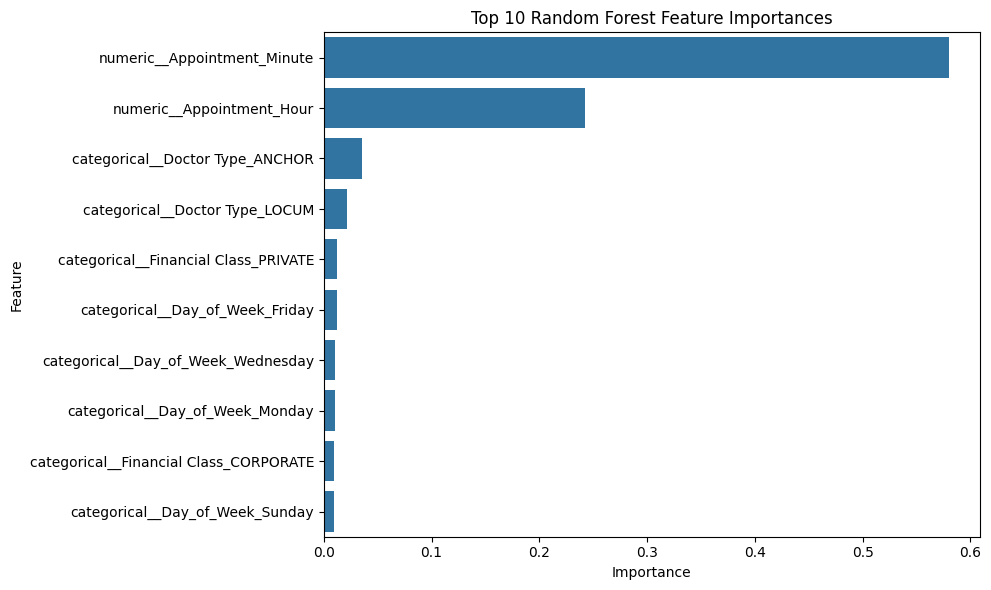

In [27]:
plt.figure(figsize=(10, 6))

top_features = importance_df.head(10)

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

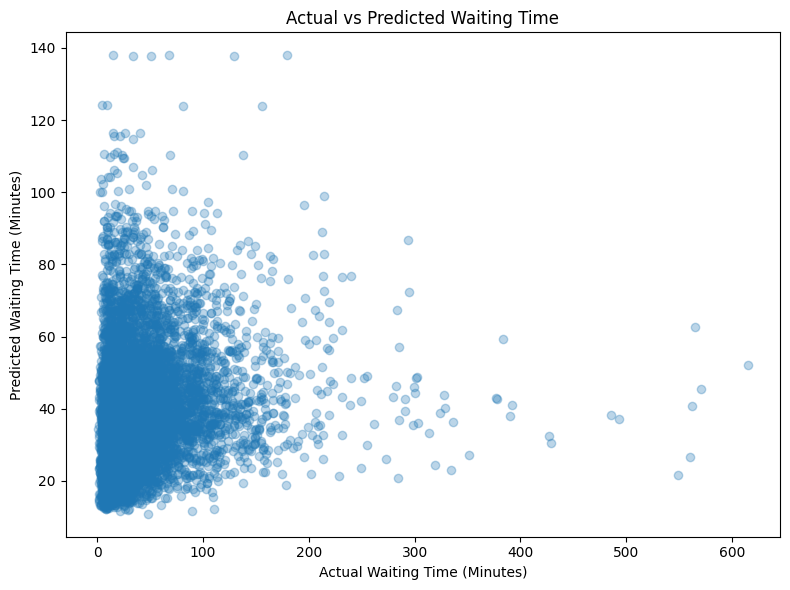

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.3
)

plt.xlabel('Actual Waiting Time (Minutes)')
plt.ylabel('Predicted Waiting Time (Minutes)')
plt.title('Actual vs Predicted Waiting Time')

plt.tight_layout()
plt.show()

In [29]:
model_results = pd.DataFrame({
    'Metric': [
        'MAE',
        'RMSE',
        'R²'
    ],
    'Value': [
        mae,
        rmse,
        r2
    ]
})

model_results

,Metric,Value
0,MAE,27.395182
1,RMSE,43.984078
2,R²,-0.027639
